# Module 5 · Scale and Long Context
**Bridge, second half → the end · 2:57–4:07**

The last claim is the biggest one: *scale is all you need*. You'll measure a scaling law on your own machine and see when a smaller model is the better buy. Then you'll follow attention's cost as context grows: the n² compute and the KV cache, FlashAttention's fix for memory traffic, million-token windows (and whether models use them), and the linear-time successors. It ends with the song's actual lesson: every state of the art becomes a baseline, and baselines are still worth running.

§5.4 reloads the LLM from Module 4 (cached, so it's quick).



In [1]:
import sys; sys.path.insert(0, '.')
from blcourse import *
import matplotlib.pyplot as plt
hardware_report()



python 3.11.15 · torch 2.15.0 · arm64 · 64 GB RAM
DEVICE = 'mps'   TIER = 'laptop'   (override: BASELINE_TIER / BASELINE_DEVICE)


---

## 5.1 Scale is all you need: a scaling law on your laptop
Kaplan et al. (2020) trained hundreds of language models and found that loss falls as a smooth **power law** in model size N, data D and compute C, over seven orders of magnitude:

$$L(N) \approx \left(\frac{N_c}{N}\right)^{\alpha_N} \quad (\alpha_N \approx 0.076) \qquad C \approx 6ND$$

Chinchilla (2022) corrected the recipe: for a fixed compute budget, grow data as fast as parameters, at roughly 20 tokens per parameter.

We'll train the same TinyGPT at several widths, on the same data and number of steps, and fit a power law with an irreducible floor: L = a·N^(−α) + c.



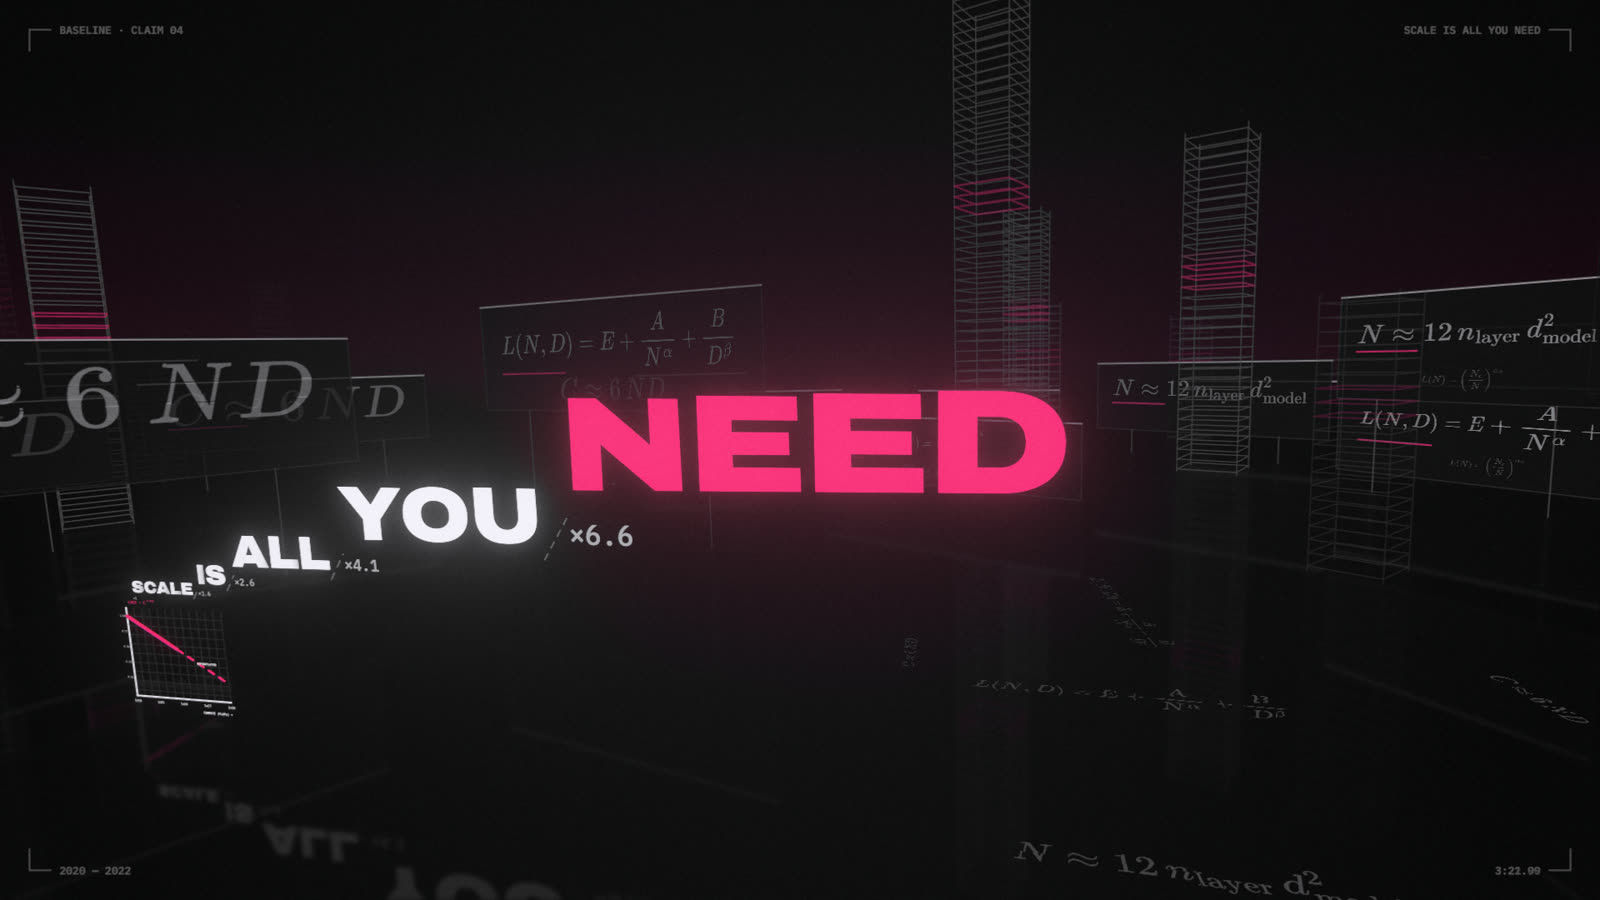

In [2]:
still(202.0)



> **Predict first.** Each width is about twice the size of the last. If the loss falls as a power law, what happens to the *improvement* per doubling as models get bigger: does it grow, stay the same, or shrink?



In [3]:
data = CharData(shakespeare())
G = CFG['gpt']; runs = []
for width in CFG['scaling_widths']:
    seed(0)
    m = TinyGPT(data.vocab, n_layer=4, n_head=4, n_embd=width, block=128)
    N = n_params(m) - m.tok.weight.numel() - m.pos.weight.numel()    # non-embedding parameters, as in Kaplan et al.
    t0 = time.perf_counter()
    hist = train_lm(m, data, CFG['scaling_steps'], 128, 32, lr=3e-3, log_every=CFG['scaling_steps'], label=f'width {width:3d}')
    tokens = CFG['scaling_steps'] * 128 * 32
    runs.append(dict(width=width, N=N, val=hist[-1][2], flops=6 * N * tokens, secs=time.perf_counter() - t0))
    del m



width  32 step   600  train 2.380  val 2.437  (10s)


width  48 step   600  train 2.249  val 2.302  (10s)


width  64 step   600  train 2.110  val 2.179  (10s)


width  96 step   600  train 1.887  val 1.961  (12s)


width 128 step   600  train 1.734  val 1.850  (14s)


width  32: N =    52,448  val 2.437  ≈7.7e+11 FLOPs  13s
width  48: N =   115,536  val 2.302  ≈1.7e+12 FLOPs  10s
width  64: N =   203,200  val 2.179  ≈3.0e+12 FLOPs  10s
width  96: N =   452,256  val 1.961  ≈6.7e+12 FLOPs  12s
width 128: N =   799,616  val 1.850  ≈1.2e+13 FLOPs  14s
extrapolated: 10× the largest model → 1.472  (floor c = 0.00)


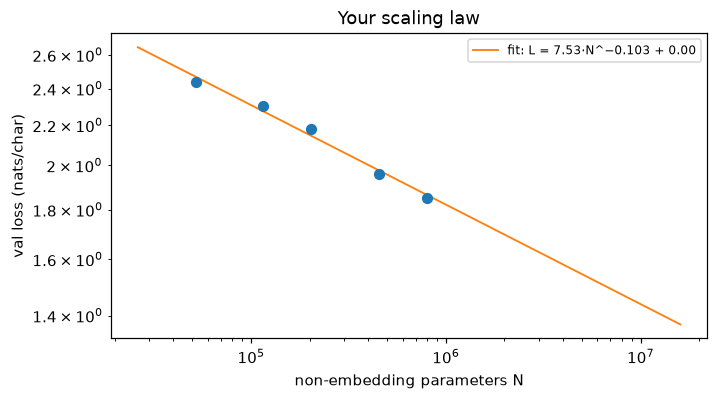

In [4]:
from scipy.optimize import curve_fit
Ns = np.array([r['N'] for r in runs], float); Ls = np.array([r['val'] for r in runs])
law = lambda n, a, alpha, c: a * n ** (-alpha) + c
# a loss floor must lie between 0 and the best loss we've seen; the exponent stays in a sane range
(a, alpha, c), _ = curve_fit(law, Ns, Ls, p0=(10, 0.3, 0.5 * Ls.min()), bounds=([0, 0, 0], [np.inf, 2, Ls.min()]), maxfev=20000)
fig, ax = plt.subplots()
ax.scatter(Ns, Ls, c='C0', s=40, zorder=3)
nn_ = np.geomspace(Ns.min() / 2, Ns.max() * 20, 100)
ax.plot(nn_, law(nn_, a, alpha, c), c='C1', lw=1.2, label=f'fit: L = {a:.2f}·N^−{alpha:.3f} + {c:.2f}')
if c > 0.01 * Ls.min():  # draw the floor only if the fit found one; a floor near 0 would stretch the log axis down to it
    ax.axhline(c, c='gray', ls=':', lw=1, label=f'floor c = {c:.2f}')
ax.set(xscale='log', yscale='log', xlabel='non-embedding parameters N', ylabel='val loss (nats/char)', title='Your scaling law'); ax.legend(fontsize=8)
for r in runs:
    print(f"width {r['width']:3d}: N = {r['N']:>9,}  val {r['val']:.3f}  ≈{r['flops']:.1e} FLOPs  {r['secs']:.0f}s")
print(f'extrapolated: 10× the largest model → {law(Ns.max() * 10, a, alpha, c):.3f}  (floor c = {c:.2f})')



**Read the fit skeptically.** On the `laptop` tier the exponent typically lands near 0.1, close to Kaplan's 0.076, but that's partly luck: character-level data, a fixed small step budget, and only five points all move it, and with this little data the floor c is barely constrained. The bigger models here are also *undertrained* (same steps for everyone), which is exactly Chinchilla's point. Still, the shape holds: steady returns per doubling, slowly flattening toward a floor. The film's gauge reads "−3.4% per doubling" with the nameplate EXTRAPOLATED.

### Try it
Double `CFG['scaling_steps']` and rerun. Which models improve most, and what does that tell you about compute-optimal size?

### Train once, serve forever: when Chinchilla isn't the right answer
Chinchilla minimizes the *training* bill for a target loss. But a deployed model is trained once and then runs on every request. Think of `-O3`: worth the extra compile time only for a binary you'll run many times. Training costs about 6·N·D FLOPs, and every generated token costs about 2·N. Compare a compute-optimal 70B with an "overtrained" 8B that got a similar training budget:



Chinchilla-style 70B · 1.4T tokens   train 5.9e+23  serve/day 1.4e+23  → serving equals training after   4.2 days
Llama-3-style 8B · 15T tokens        train 7.2e+23  serve/day 1.6e+22  → serving equals training after  45.0 days


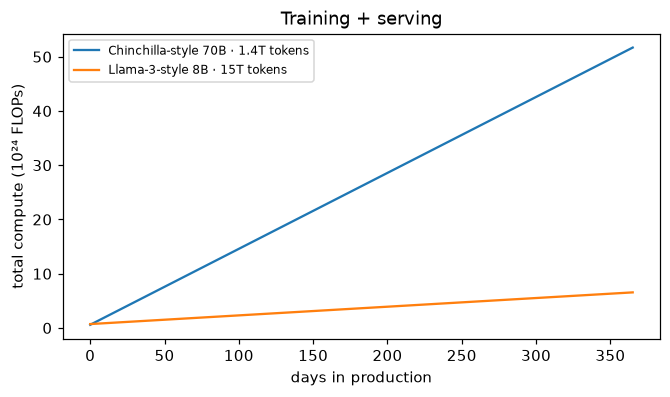

In [5]:
def train_flops(N, D): return 6 * N * D
def serve_flops(N, tokens): return 2 * N * tokens

models = {'Chinchilla-style 70B · 1.4T tokens': (70e9, 1.4e12), 'Llama-3-style 8B · 15T tokens': (8e9, 15e12)}
served_per_day = 1e12                                         # a popular product: a trillion tokens a day
for name, (N, D) in models.items():
    t, s = train_flops(N, D), serve_flops(N, served_per_day)
    print(f'{name:36s} train {t:.1e}  serve/day {s:.1e}  → serving equals training after {t / s:5.1f} days')

days = np.arange(0, 366)
fig, ax = plt.subplots()
for (name, (N, D)), c in zip(models.items(), ('C0', 'C1')):
    ax.plot(days, (train_flops(N, D) + serve_flops(N, served_per_day) * days) / 1e24, c=c, label=name)
ax.set(xlabel='days in production', ylabel='total compute (10²⁴ FLOPs)', title='Training + serving'); ax.legend(fontsize=8);



The two training bills are about the same, but the 8B serves each token for about a ninth of the compute, and the gap grows every day it's in production. That's why widely deployed models are usually small ones trained far past the Chinchilla point. The price is a somewhat higher loss than the 70B would reach. Change `served_per_day` to 1e9 (a niche internal tool) and see how the answer changes.



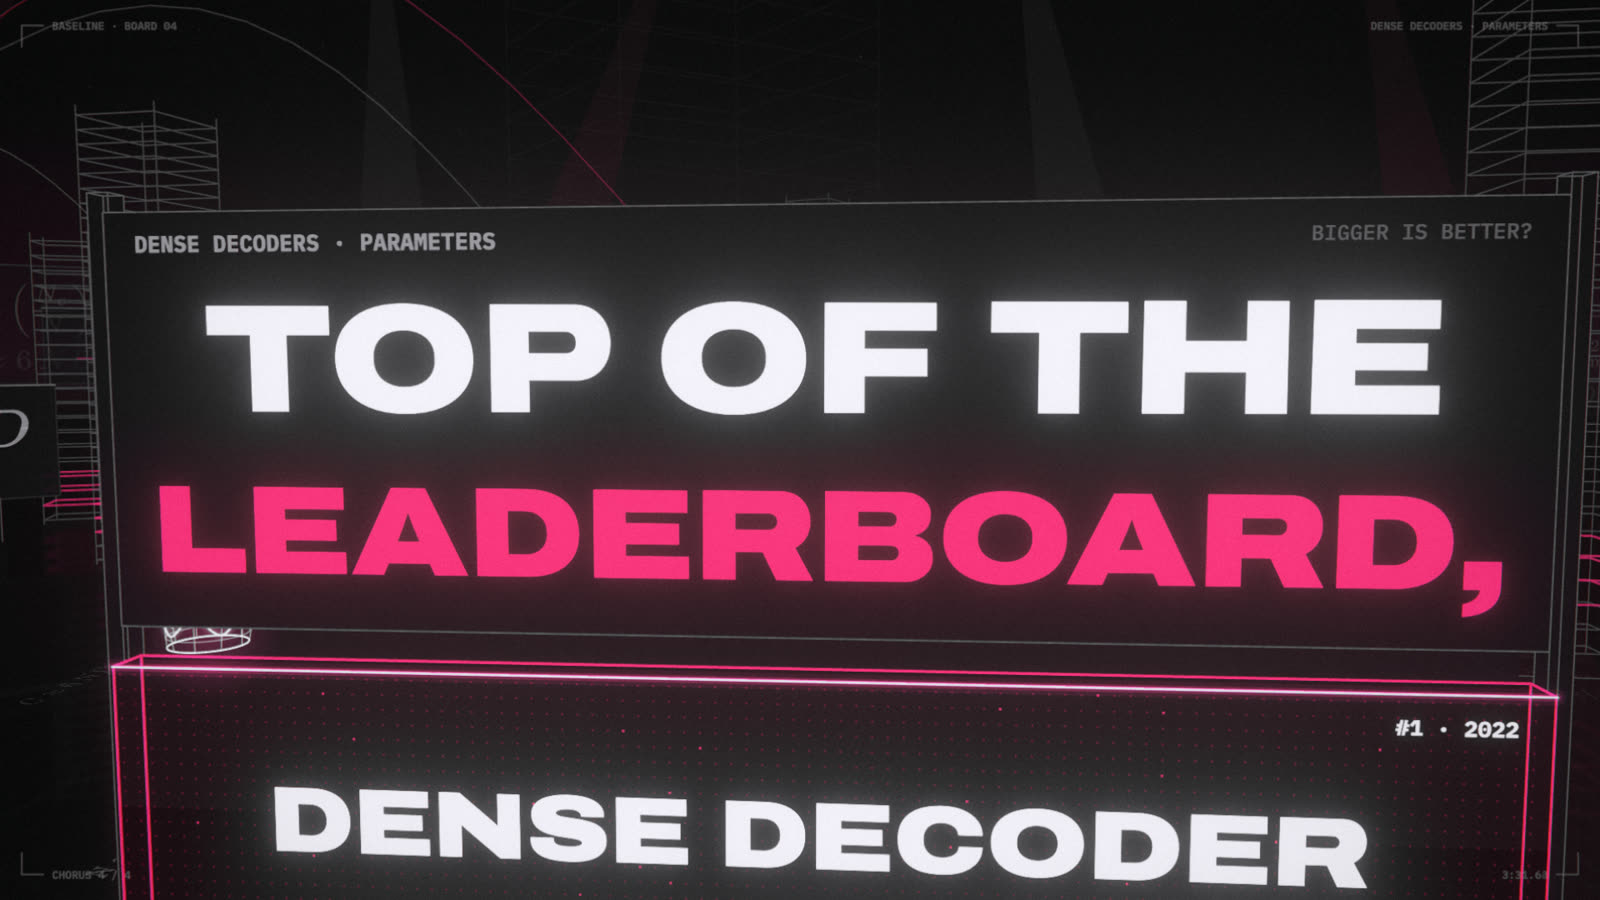

In [6]:
still(211.64)



---

## 5.2 And you, attention: quadratic in the length
Self-attention compares every token with every other token: n² scores per head per layer. Double the context and the attention cost goes up 4×. FlashAttention (next section) fixes the *memory* traffic, not the *arithmetic*.

During generation there's a second cost: the **KV cache**. To produce token n+1, the model needs the keys and values of all n previous tokens, so memory grows linearly with context:



In [7]:
def kv_cache_gb(n_tokens, layers=32, kv_heads=8, head_dim=128, bytes_=2):
    return 2 * layers * kv_heads * head_dim * bytes_ * n_tokens / 2**30          # K and V, every layer
for n in (2_048, 32_768, 131_072, 1_048_576):
    print(f'{n:>9,} tokens: KV cache ≈ {kv_cache_gb(n):6.1f} GB  (a 7–8B-class model with grouped-query attention, bf16)')



    2,048 tokens: KV cache ≈    0.2 GB  (a 7–8B-class model with grouped-query attention, bf16)
   32,768 tokens: KV cache ≈    4.0 GB  (a 7–8B-class model with grouped-query attention, bf16)
  131,072 tokens: KV cache ≈   16.0 GB  (a 7–8B-class model with grouped-query attention, bf16)
1,048,576 tokens: KV cache ≈  128.0 GB  (a 7–8B-class model with grouped-query attention, bf16)


### Your turn: KV-cache size for any model
Generalize `kv_cache_gb` above: return the cache size in **bytes** for a model with `layers` layers, `kv_heads` key/value heads of size `head_dim`, `n_tokens` tokens of context, and `bytes_per` bytes per number. Then try it on the course's own LLM: Qwen2.5-0.5B has 24 layers, 2 KV heads and head size 64.



In [8]:
def kv_cache_bytes(layers, kv_heads, head_dim, n_tokens, bytes_per):
    """Bytes of keys + values cached for n_tokens of context."""
    raise NotImplementedError        # your code here: one line

check('kv_cache_bytes', kv_cache_bytes)



⏳ kv_cache_bytes: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


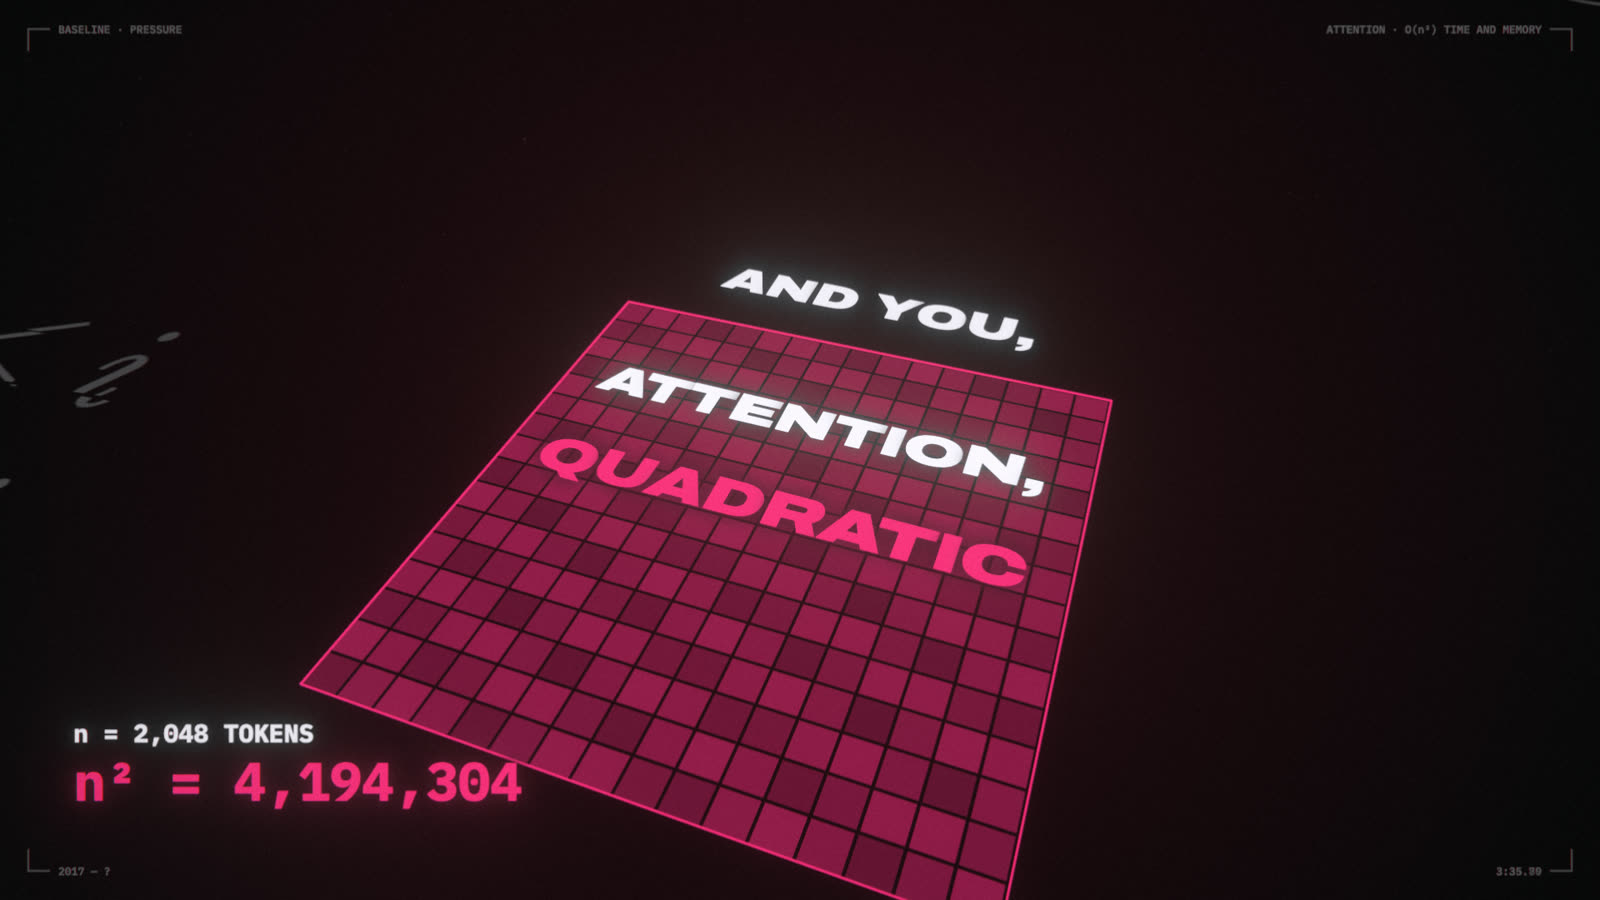

In [9]:
still(215.8)



---

## 5.3 FlashAttention tiles it all inside the SRAM
Standard attention computes the full n × n score matrix S = QKᵀ, writes it to GPU main memory (HBM), reads it back for the softmax, writes the result, and reads it again to multiply by V. For n = 32K that's 1 billion entries per head. The arithmetic is cheap. The **memory traffic** is the bottleneck.

FlashAttention is built from two ideas that have nothing to do with ML. Try each one on its own first.

### Stepping stone 1: a matrix multiply works in tiles
Each cell of C = A·B is a row of A dotted with a column of B. Split the shared dimension into blocks and add up the block products, and you get the same C, up to float rounding, because the additions happen in a different order. But each block is small enough to sit in fast memory while you use it. CPU math libraries call this **loop tiling** (or cache blocking) and have done it for decades.



In [10]:
seed(0)
A, B = torch.randn(256, 512), torch.randn(512, 128)
C_tiled = torch.zeros(256, 128)
for k0 in range(0, 512, 64):                      # walk the shared dimension 64 columns at a time
    C_tiled += A[:, k0:k0 + 64] @ B[k0:k0 + 64, :]  # each partial product only needs one tile of A and one of B
print('max |A@B − tiled| =', (A @ B - C_tiled).abs().max().item())



max |A@B − tiled| = 7.62939453125e-05


### Stepping stone 2: a softmax as running totals
A softmax needs two things about its row: the max (subtracted first so `exp` can't overflow) and the sum of exps. You can get both from a stream, one chunk at a time, without storing the stream. Just keep a running max and a running sum. When a new chunk raises the max, the sum you already have was computed against the old max, so multiply it by e^(old max − new max) to bring it up to date.



**Your turn first.** Write the streaming version: given the scores in chunks, return the max and the sum of exp(score − max), touching each chunk once. When a new chunk raises the max, the sum you already have was computed against the old max, so multiply it by e^(old max − new max) before adding the new chunk.



In [11]:
def stream_softmax(chunks):
    """chunks: a sequence of 1-D tensors. Return (max of all scores, sum of exp(score − max))."""
    raise NotImplementedError        # your code here: about 5 lines

check('stream_softmax', stream_softmax)



⏳ stream_softmax: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


Here is the same idea worked through, checked against computing it all at once:



In [12]:
scores = torch.randn(10_000) * 3
m, l = -float('inf'), 0.0
for chunk in scores.split(1000):                   # pretend the scores arrive 1,000 at a time
    m_new = max(m, chunk.max().item())
    l = l * math.exp(m - m_new) + torch.exp(chunk - m_new).sum().item()   # rescale the old sum, add the new chunk
    m = m_new
print(f'streamed: max {m:.4f}  sum {l:.4f}')
print(f'all at once: max {scores.max().item():.4f}  sum {torch.exp(scores - scores.max()).sum().item():.4f}')



streamed: max 11.4869  sum 9.5433
all at once: max 11.4869  sum 9.5433


### Putting them together
**FlashAttention** (Dao et al., 2022) never stores S. It walks over K and V one tile at a time, like stepping stone 1, inside the GPU's small on-chip SRAM. For each query row it keeps the running max m and running sum ℓ from stepping stone 2 (the **online softmax**), plus a running weighted sum of V that gets the same rescaling. The result is *exactly* the same attention, with memory linear in n. Here it is in plain PyTorch:



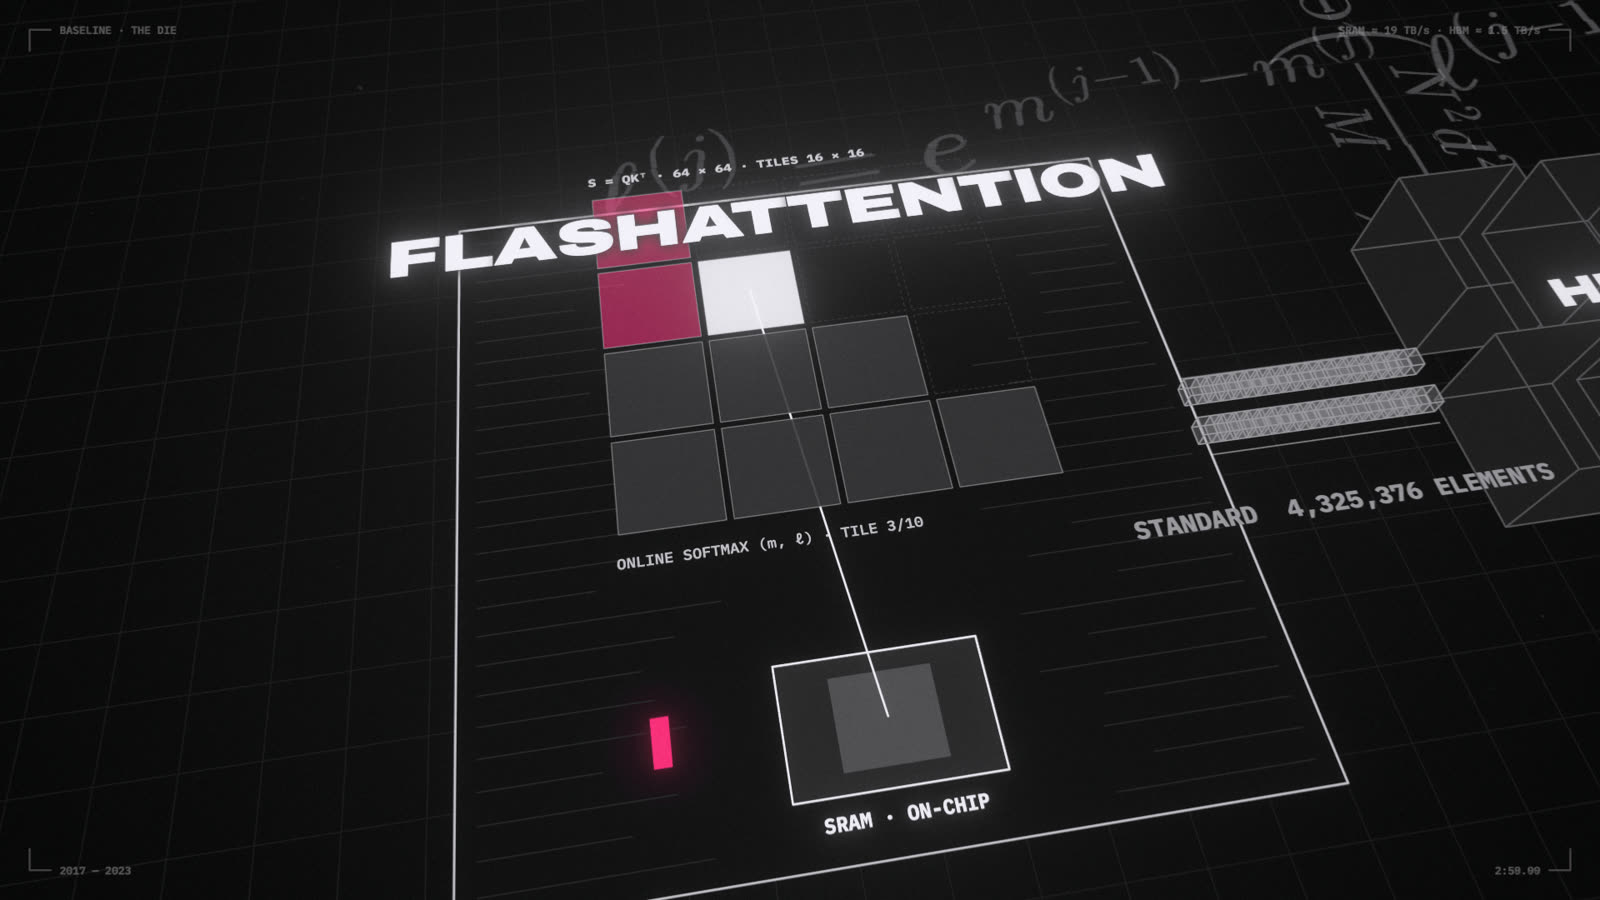

In [13]:
still(179.0)



In [14]:
def naive_attention(q, k, v):
    S = (q @ k.transpose(-1, -2)) / math.sqrt(q.shape[-1])          # n × n, materialized
    return S.softmax(-1) @ v

def tiled_attention(q, k, v, tile=128):
    """Online-softmax attention over K/V tiles. Never holds more than n × tile scores."""
    scale = 1 / math.sqrt(q.shape[-1])
    m = torch.full(q.shape[:-1], -float('inf'), device=q.device)      # running row max
    l = torch.zeros(q.shape[:-1], device=q.device)                   # running row sum of exp
    acc = torch.zeros_like(q)
    for j in range(0, k.shape[-2], tile):
        s = (q @ k[..., j:j + tile, :].transpose(-1, -2)) * scale     # n × tile
        m_new = torch.maximum(m, s.amax(-1))
        p = torch.exp(s - m_new[..., None])
        corr = torch.exp(m - m_new)                                   # rescale what we had so far
        l = l * corr + p.sum(-1)
        acc = acc * corr[..., None] + p @ v[..., j:j + tile, :]
        m = m_new
    return acc / l[..., None]

seed(0)
q, k, v = (torch.randn(1, 4, 1024, 64, device=DEVICE) for _ in range(3))
print('max |naive − tiled| =', (naive_attention(q, k, v) - tiled_attention(q, k, v)).abs().max().item())
print('max |naive − torch SDPA| =', (naive_attention(q, k, v) - F.scaled_dot_product_attention(q, k, v)).abs().max().item())



max |naive − tiled| = 3.2782554626464844e-07
max |naive − torch SDPA| = 5.364418029785156e-07


Same numbers. Now the costs.

> **Predict first.** As n doubles from 256 upward, how much slower does naive attention get per doubling? And will PyTorch's fused kernel be faster at small n, large n, or both?
`F.scaled_dot_product_attention` (SDPA) is PyTorch's fused kernel, which uses FlashAttention-style kernels on CUDA and an efficient kernel on MPS/CPU. The pure-Python tiled version shows the *algorithm*. It isn't fast, because Python can't keep the tile in SRAM. That's why FlashAttention is written as a custom GPU kernel.



n=   256  naive      0.4 ms   SDPA      0.2 ms   naive score matrix        1 MB
n=   512  naive      0.6 ms   SDPA      0.3 ms   naive score matrix        4 MB
n=  1024  naive      1.4 ms   SDPA      1.1 ms   naive score matrix       16 MB


n=  2048  naive      4.3 ms   SDPA      3.1 ms   naive score matrix       64 MB


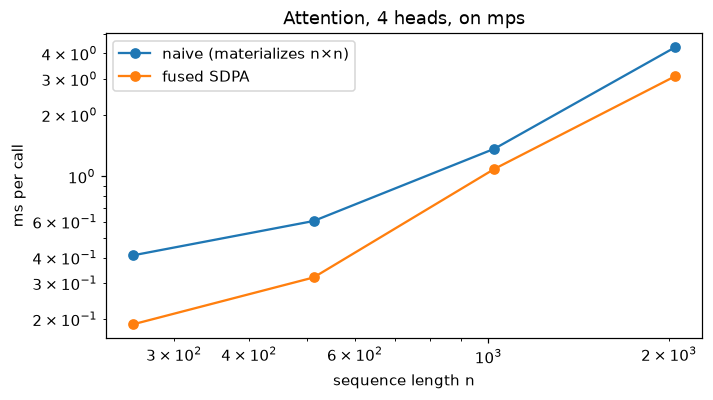

In [15]:
def bench(fn, n, H=4, d=64, reps=3):
    q, k, v = (torch.randn(1, H, n, d, device=DEVICE) for _ in range(3))
    try:
        fn(q, k, v); sync(); t0 = time.perf_counter()
        for _ in range(reps):
            fn(q, k, v)
        sync(); return (time.perf_counter() - t0) / reps * 1e3
    except (RuntimeError, MemoryError):                               # out of memory is itself the lesson
        return float('nan')

rows = []
for n in CFG['attn_lengths']:
    rows.append((n, bench(naive_attention, n), bench(F.scaled_dot_product_attention, n), 4 * n * n * 4 / 2**20))
    print(f'n={n:6d}  naive {rows[-1][1]:8.1f} ms   SDPA {rows[-1][2]:8.1f} ms   naive score matrix {rows[-1][3]:8.0f} MB')
ns = [r[0] for r in rows]
fig, ax = plt.subplots()
ax.plot(ns, [r[1] for r in rows], 'o-', label='naive (materializes n×n)'); ax.plot(ns, [r[2] for r in rows], 'o-', label='fused SDPA')
ax.set(xscale='log', yscale='log', xlabel='sequence length n', ylabel='ms per call', title=f'Attention, 4 heads, on {DEVICE}'); ax.legend();



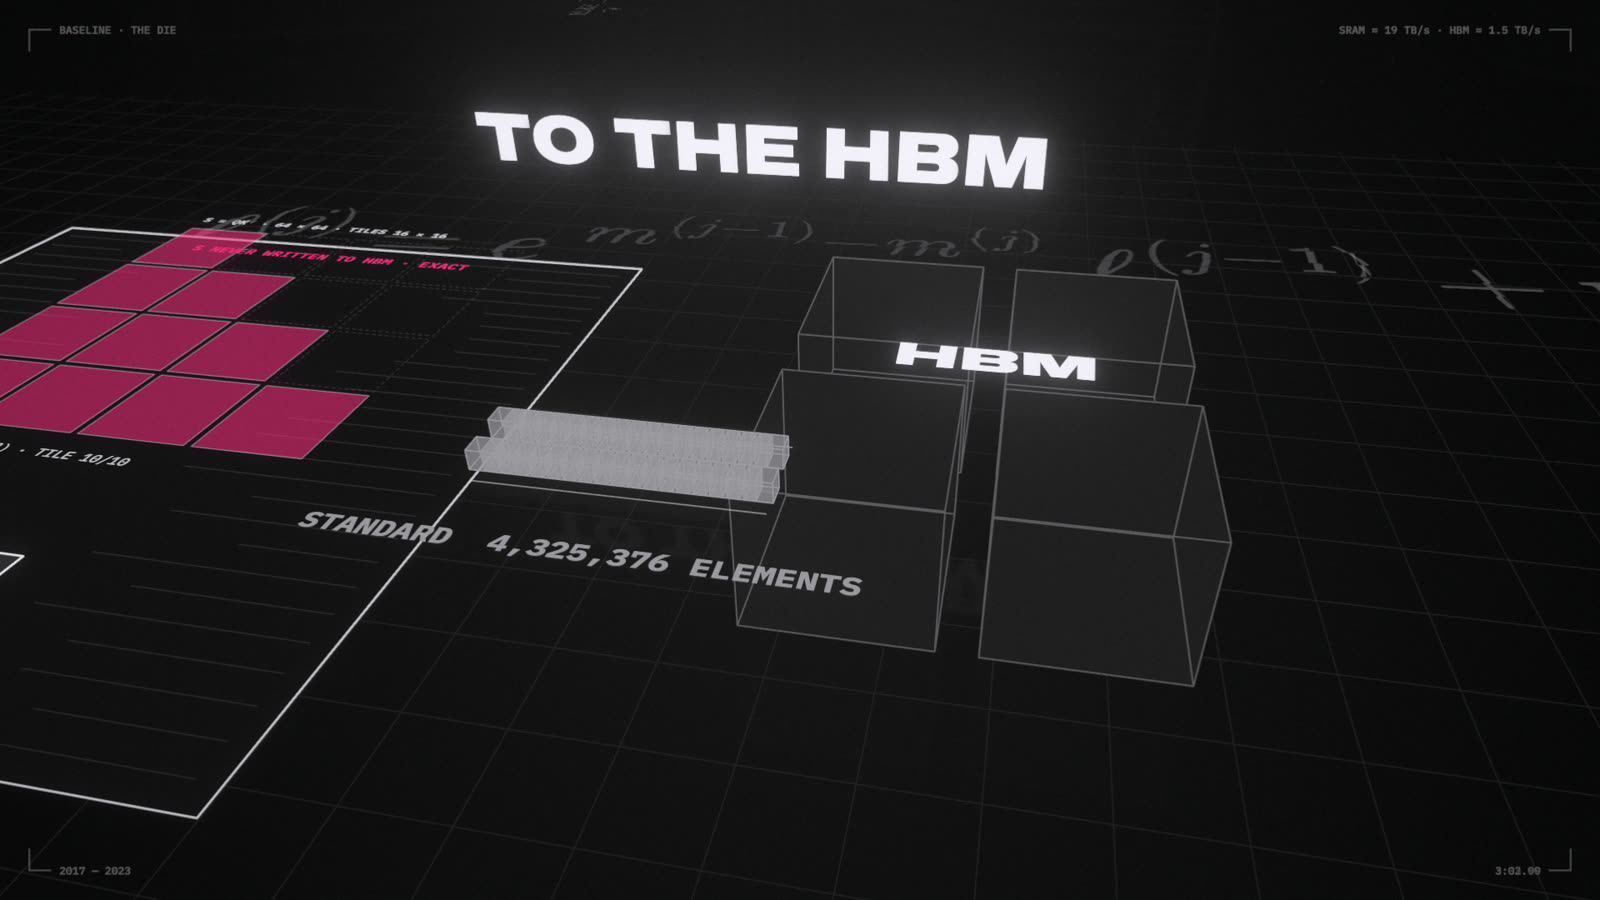

In [16]:
still(183.0)



---

## 5.4 Context window: 2K, then a million tokens long
GPT-3 read 2,048 tokens at a time. Gemini 1.5 (2024) read a million. Longer context needed cheaper attention (above), better position encodings (RoPE with scaled frequencies), and long-document training data. But does a model actually *use* a long context?

> **Predict first.** At the longest length your tier tries, will the model still find the password at every depth? Which depths are hardest?

**Needle in a haystack**: hide one fact at some depth inside long filler text, then ask for it. Sweep context length × depth. Your tier's LLM and lengths are below. Wherever your model starts missing needles, that is the result.



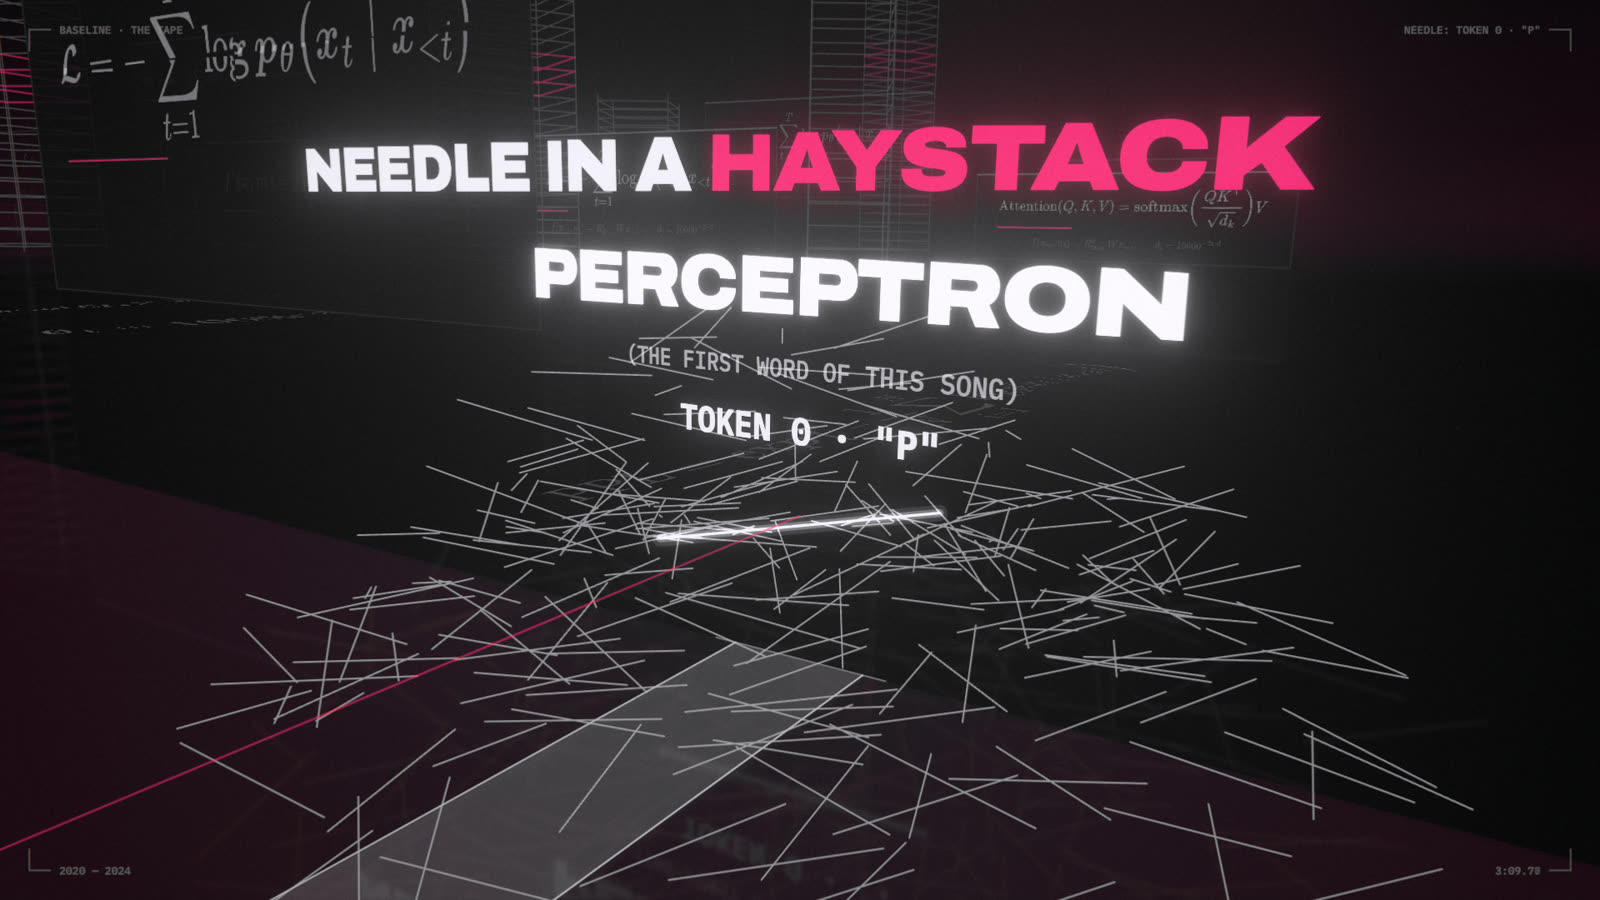

In [17]:
still(189.77)



Qwen/Qwen2.5-0.5B-Instruct: 494M parameters, torch.float32, on mps


   256 tokens: 5/5 found   (last answer: 'MAGENTA-1958')


   512 tokens: 5/5 found   (last answer: 'MAGENTA-1958')


  1024 tokens: 5/5 found   (last answer: 'MAGENTA-1958')


  2048 tokens: 5/5 found   (last answer: 'MAGENTA-1958')
needle in a haystack: 8.69s


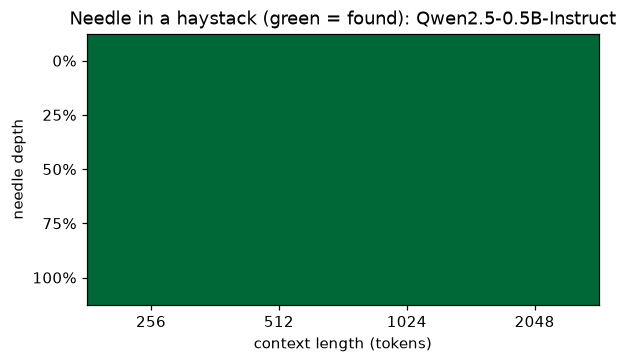

In [18]:
NEEDLE = 'The secret password for the vault is MAGENTA-1958.'
QUESTION = 'What is the secret password for the vault? Reply with the password only.'
tok, llm = load_llm()                 # the LLM from Module 4, cached on disk
hay_ids = tok(shakespeare()[:400_000])['input_ids']

def niah(length, depth):
    body = hay_ids[:length]; cut = int(depth * len(body))
    text = tok.decode(body[:cut]) + '\n' + NEEDLE + '\n' + tok.decode(body[cut:])
    out = chat(tok, llm, f'{text}\n\n{QUESTION}', 12)
    return 'MAGENTA-1958' in out.upper().replace(' ', ''), out

grid = np.zeros((len(CFG['niah_depths']), len(CFG['niah_lengths'])))
with timer('needle in a haystack:'):
    for j, L in enumerate(CFG['niah_lengths']):
        for i, d in enumerate(CFG['niah_depths']):
            ok, out = niah(L, d); grid[i, j] = ok
        print(f'{L:6d} tokens: {int(grid[:, j].sum())}/{len(CFG["niah_depths"])} found   (last answer: {out!r})')

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.imshow(grid, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto'); ax.grid(False)
ax.set(xticks=range(len(CFG['niah_lengths'])), xticklabels=CFG['niah_lengths'], yticks=range(len(CFG['niah_depths'])),
       yticklabels=[f'{d:.0%}' for d in CFG['niah_depths']], xlabel='context length (tokens)', ylabel='needle depth',
       title=f'Needle in a haystack (green = found): {CFG["llm"].split("/")[-1]}');



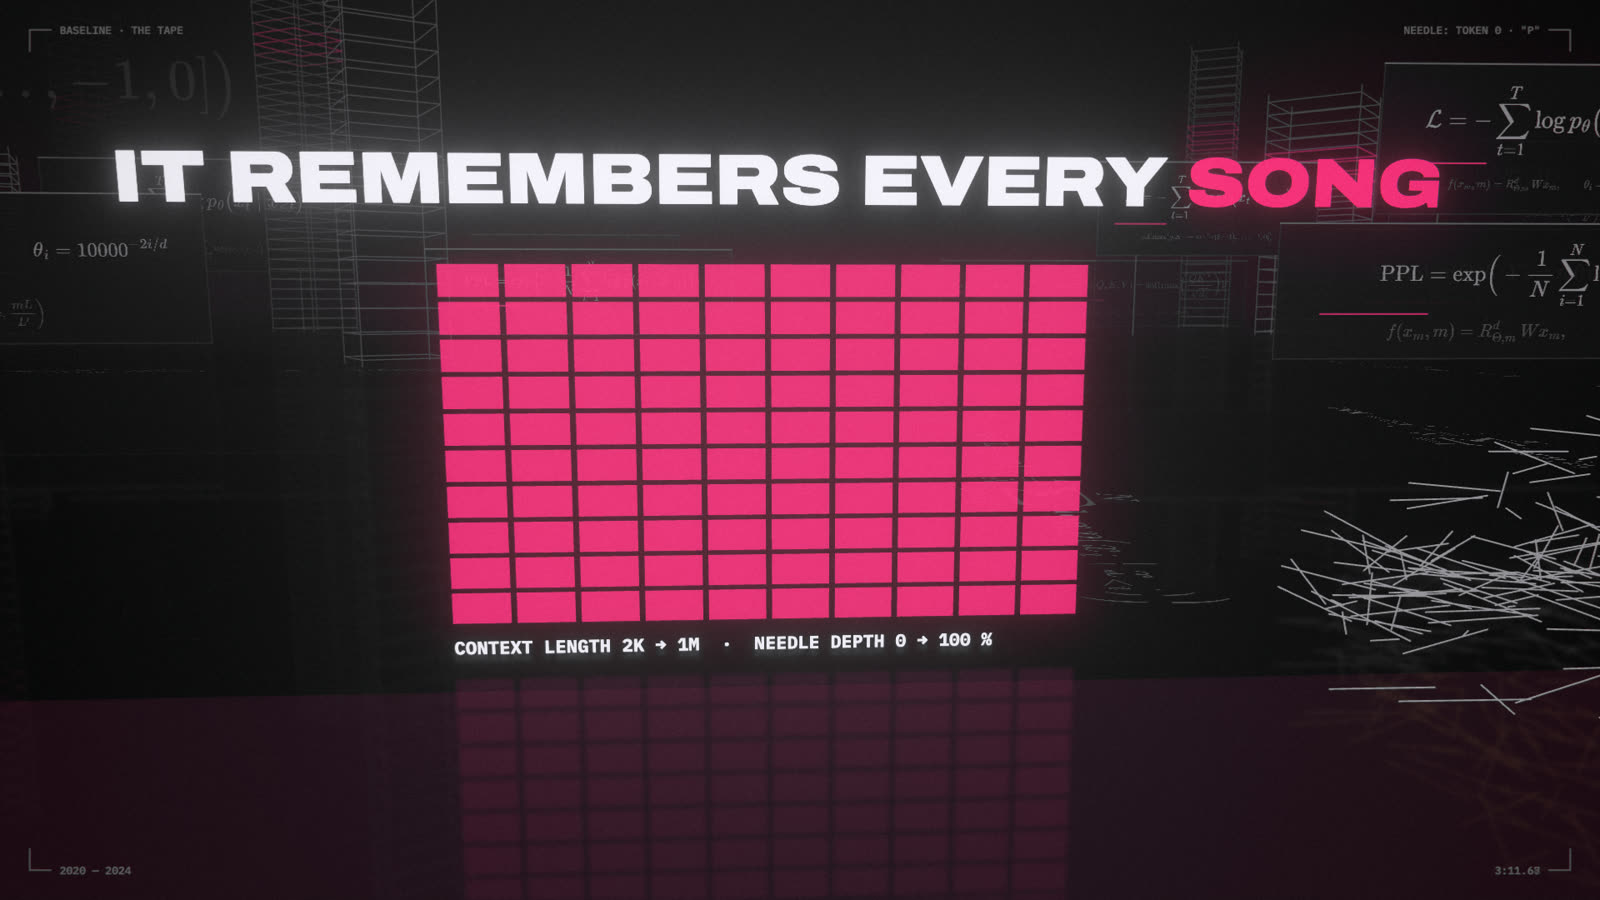

In [19]:
still(191.68)



Passing needle-in-a-haystack is necessary but nowhere near sufficient. Finding one planted sentence is much easier than *reasoning* over a whole long document. Newer benchmarks (RULER, multi-needle, long-document QA) test that, and they're much harder.



---

## 5.5 A linear-time successor, training up its strength
Recurrent models had a fixed-size state and O(n) cost. Their problems were sequential training and forgetting. A family of newer models brings the recurrence back in a form that trains in parallel: **linear attention**, **state-space models** (S4, Mamba), **RWKV**, and gated variants. The simplest is linear attention (Katharopoulos et al., 2020). Drop the softmax, use a positive feature map φ, and associativity lets you carry a d × d running state instead of all past keys:

$$o_t = \frac{\phi(q_t)^\top S_t}{\phi(q_t)^\top z_t}, \qquad S_t = S_{t-1} + \phi(k_t)\,v_t^\top, \quad z_t = z_{t-1} + \phi(k_t)$$

Per token, that's constant work and constant memory, whatever the context length. Training uses a **chunked** form: exact attention inside each chunk, plus the carried state between chunks.



In [20]:
phi = lambda x: F.elu(x) + 1

def linear_attention_chunked(q, k, v, chunk=128):
    q, k = phi(q), phi(k)
    B, H, n, d = q.shape
    S = torch.zeros(B, H, d, v.shape[-1], device=q.device); z = torch.zeros(B, H, d, device=q.device)
    mask = torch.tril(torch.ones(chunk, chunk, device=q.device))
    out = []
    for i in range(0, n, chunk):
        qc, kc, vc = q[..., i:i + chunk, :], k[..., i:i + chunk, :], v[..., i:i + chunk, :]
        c = qc.shape[-2]; A = (qc @ kc.transpose(-1, -2)) * mask[:c, :c]          # causal, within the chunk
        num = qc @ S + A @ vc
        den = (qc @ z[..., None])[..., 0] + A.sum(-1)
        out.append(num / den[..., None])
        S = S + kc.transpose(-1, -2) @ vc; z = z + kc.sum(-2)                      # carry the state forward
    return torch.cat(out, -2)

def linear_attention_reference(q, k, v):                                         # O(n²) form, for checking
    q, k = phi(q), phi(k)
    A = torch.tril(q @ k.transpose(-1, -2))
    return (A @ v) / A.sum(-1, keepdim=True)

seed(0); q, k, v = (torch.randn(1, 2, 300, 32, device=DEVICE) for _ in range(3))
print('chunked vs reference, max abs diff:', (linear_attention_chunked(q, k, v) - linear_attention_reference(q, k, v)).abs().max().item())



chunked vs reference, max abs diff: 1.7881393432617188e-07


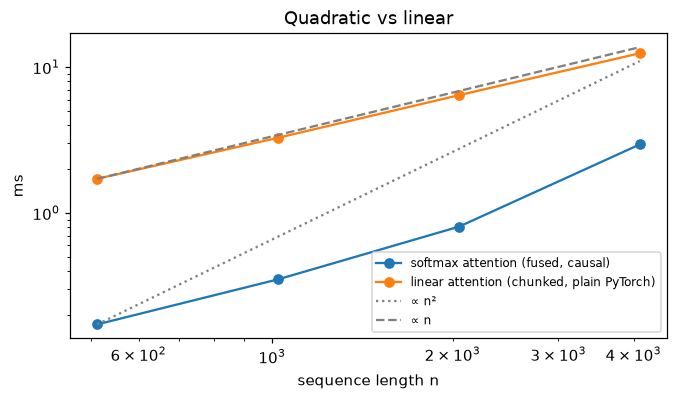

In [21]:
# bench() is the one from §5.3
# > Predict first (in your head): softmax attention's time grows like n², linear attention's like n. At these lengths, which is faster in absolute terms?
lengths = [n * 2 for n in CFG['attn_lengths']]
soft = [bench(lambda q, k, v: F.scaled_dot_product_attention(q, k, v, is_causal=True), n) for n in lengths]
lin = [bench(linear_attention_chunked, n) for n in lengths]
fig, ax = plt.subplots()
ax.plot(lengths, soft, 'o-', label='softmax attention (fused, causal)')
ax.plot(lengths, lin, 'o-', label='linear attention (chunked, plain PyTorch)')
ax.plot(lengths, [soft[0] * (n / lengths[0]) ** 2 for n in lengths], ':', c='gray', label='∝ n²')
ax.plot(lengths, [lin[0] * (n / lengths[0]) for n in lengths], '--', c='gray', label='∝ n')
ax.set(xscale='log', yscale='log', xlabel='sequence length n', ylabel='ms', title='Quadratic vs linear'); ax.legend(fontsize=8);



A highly optimized fused kernel can beat plain-PyTorch linear attention at short lengths. Watch the slopes, though: one curve tracks n², the other n, so past some length the linear one always wins. Whether linear-time models match attention's *quality* is still open. Pure linear attention recalls exact tokens worse, which is why most current long-context models are **hybrids** that mix a few attention layers with many linear or state-space layers. The song puts it as a successor "training up its strength".



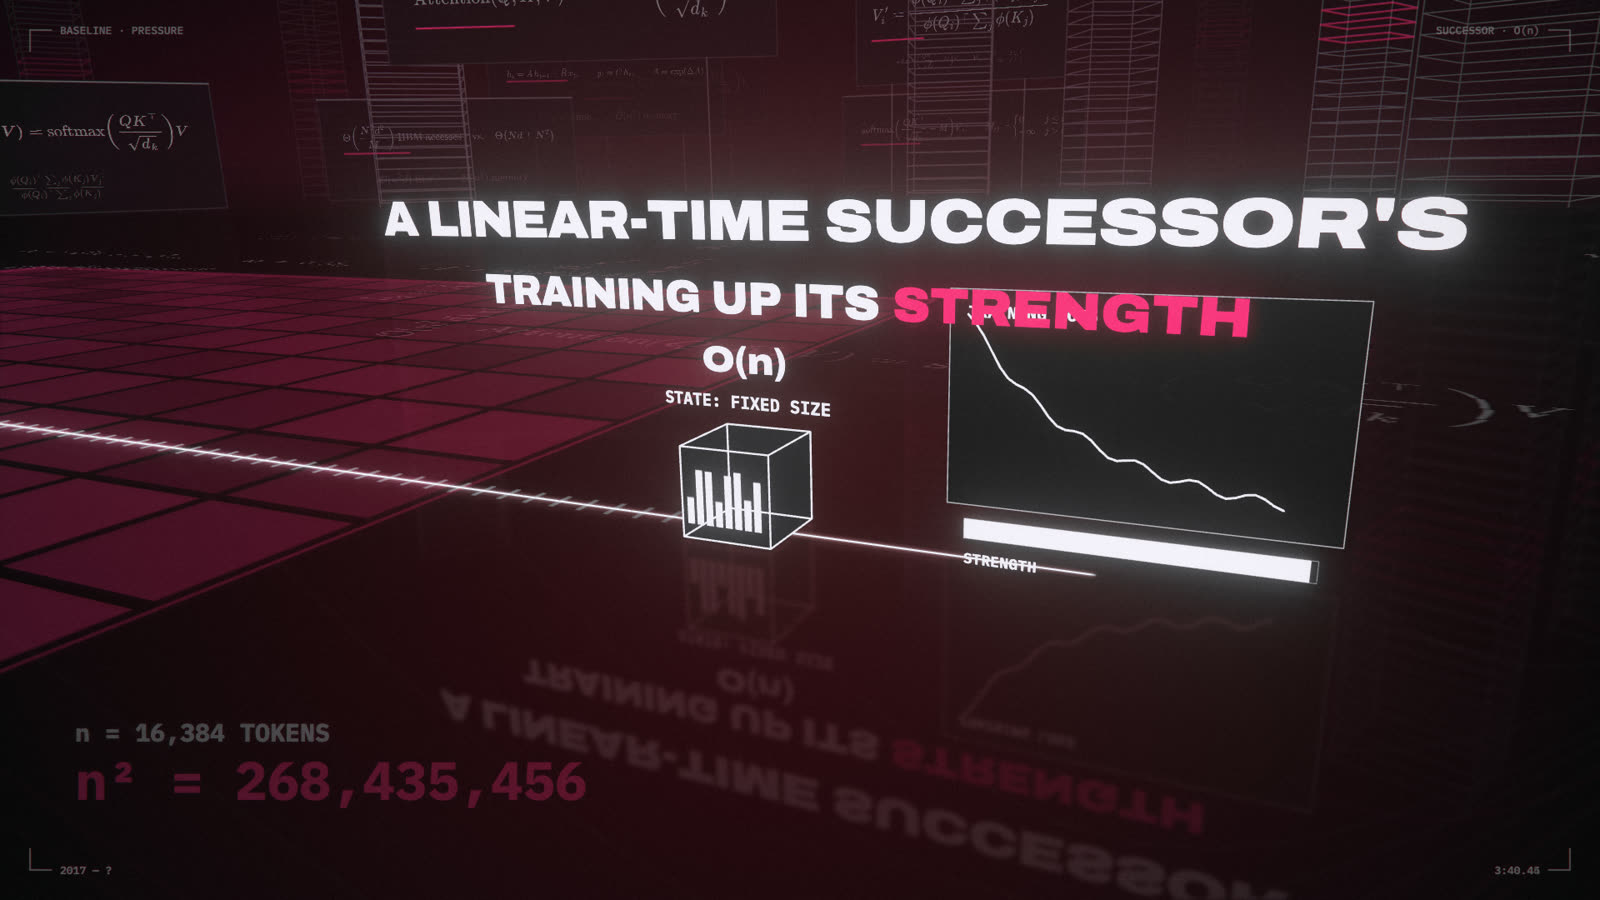

In [22]:
still(220.45)



---

## 5.6 Every "all you need" becomes a footnote
The song's four claims, each a paper with a date:

| claim | paper | date | what replaced or absorbed it |
|---|---|---|---|
| Memory's all you need | LSTM, Hochreiter & Schmidhuber | 1997-11-15 | attention / Transformers |
| Depth is all you need | ResNet, He et al. | 2015-12-10 | the residual stream lives on in every Transformer |
| Attention's all you need | Transformer, Vaswani et al. | 2017-06-12 | still standing; hybrids with linear-time layers are rising |
| Scale is all you need | Scaling laws, Kaplan et al. | 2020-01-23 | Chinchilla's data-optimal scaling, then test-time compute |



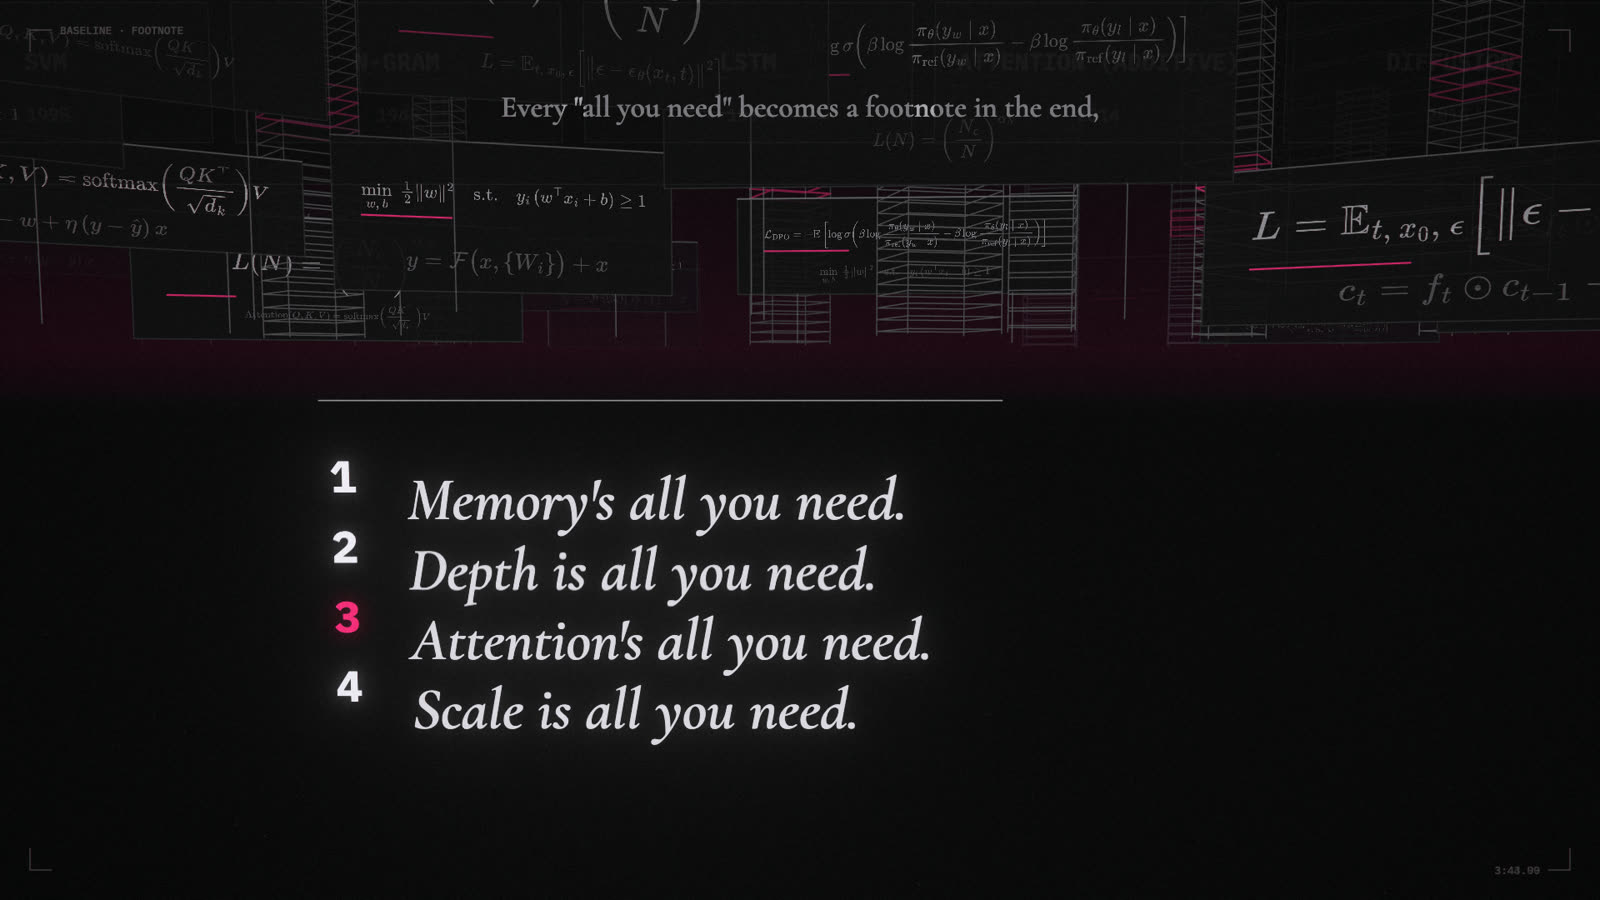

In [23]:
still(224.0)



### The developer's takeaway: always run the baseline
"Baseline" is the song's insult, but in practice it's the most useful word in this course. Before you reach for a large model, **build the cheapest thing that could work, and measure it on a held-out set**:

| if your problem is… | try this baseline first | covered in |
|---|---|---|
| tabular data (rows and columns) | gradient-boosted trees or logistic regression. These still often beat deep nets here | 0, 1 |
| text classification | TF-IDF + linear model, or embeddings + logistic regression | 1, 2 |
| autocomplete over a small domain | n-gram counts | 2 |
| "make the LLM answer in our format" | a few-shot prompt, then LoRA | 3 |
| "make the LLM know our documents" | retrieval into the prompt, not fine-tuning | 3, 4 |

A baseline tells you whether the fancy model is earning its cost, and it's how every number on every leaderboard in this song was judged.



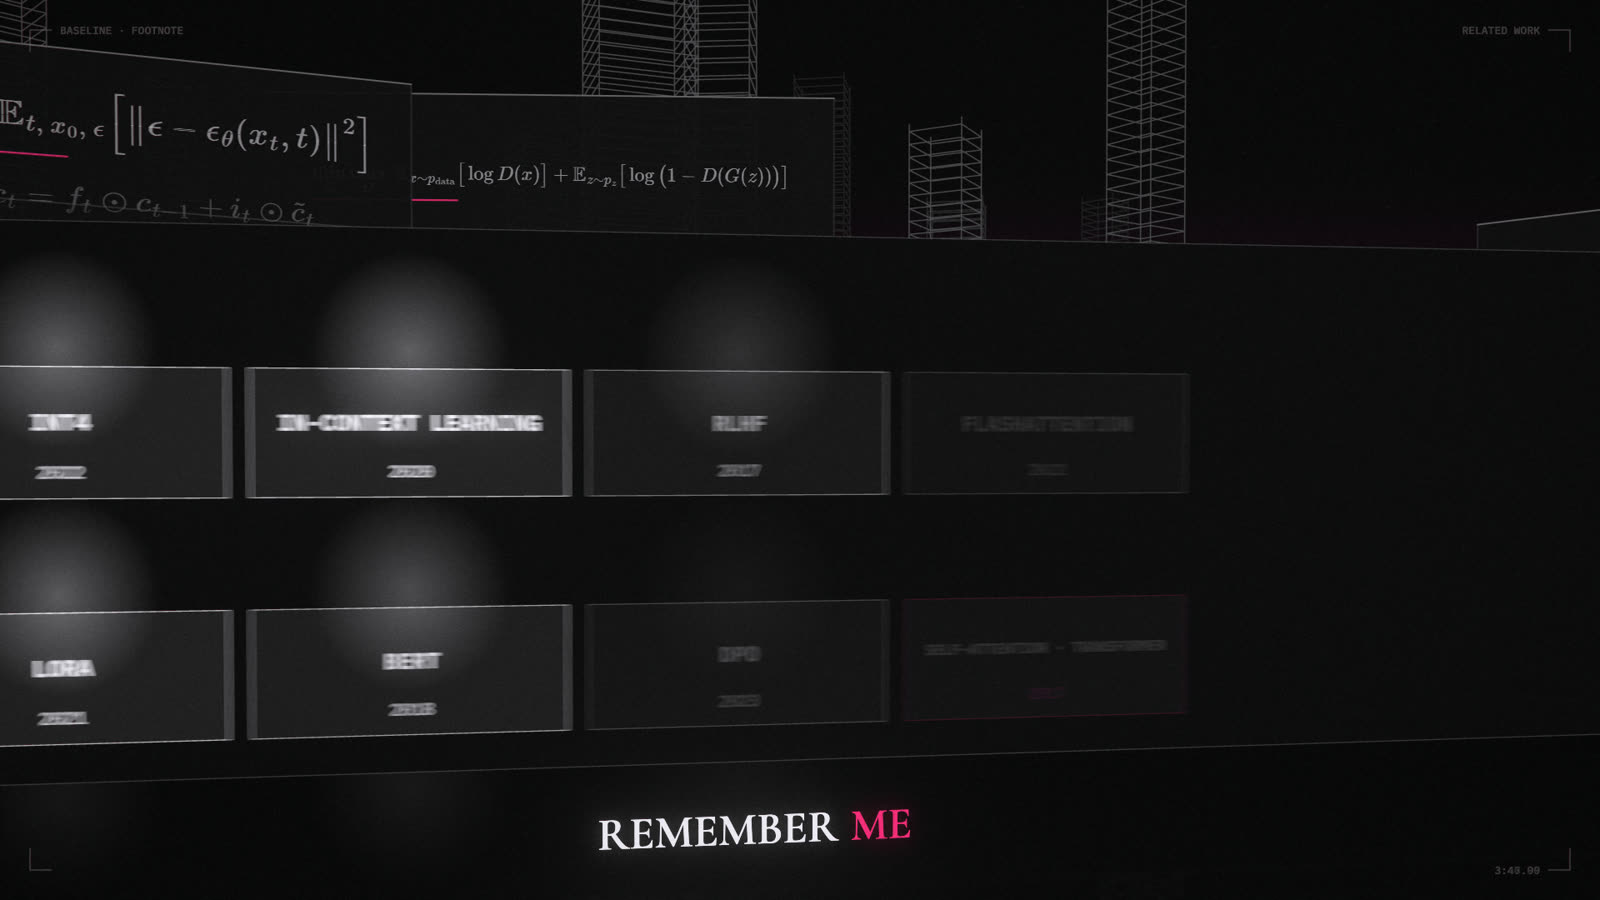

In [24]:
still(227.0)



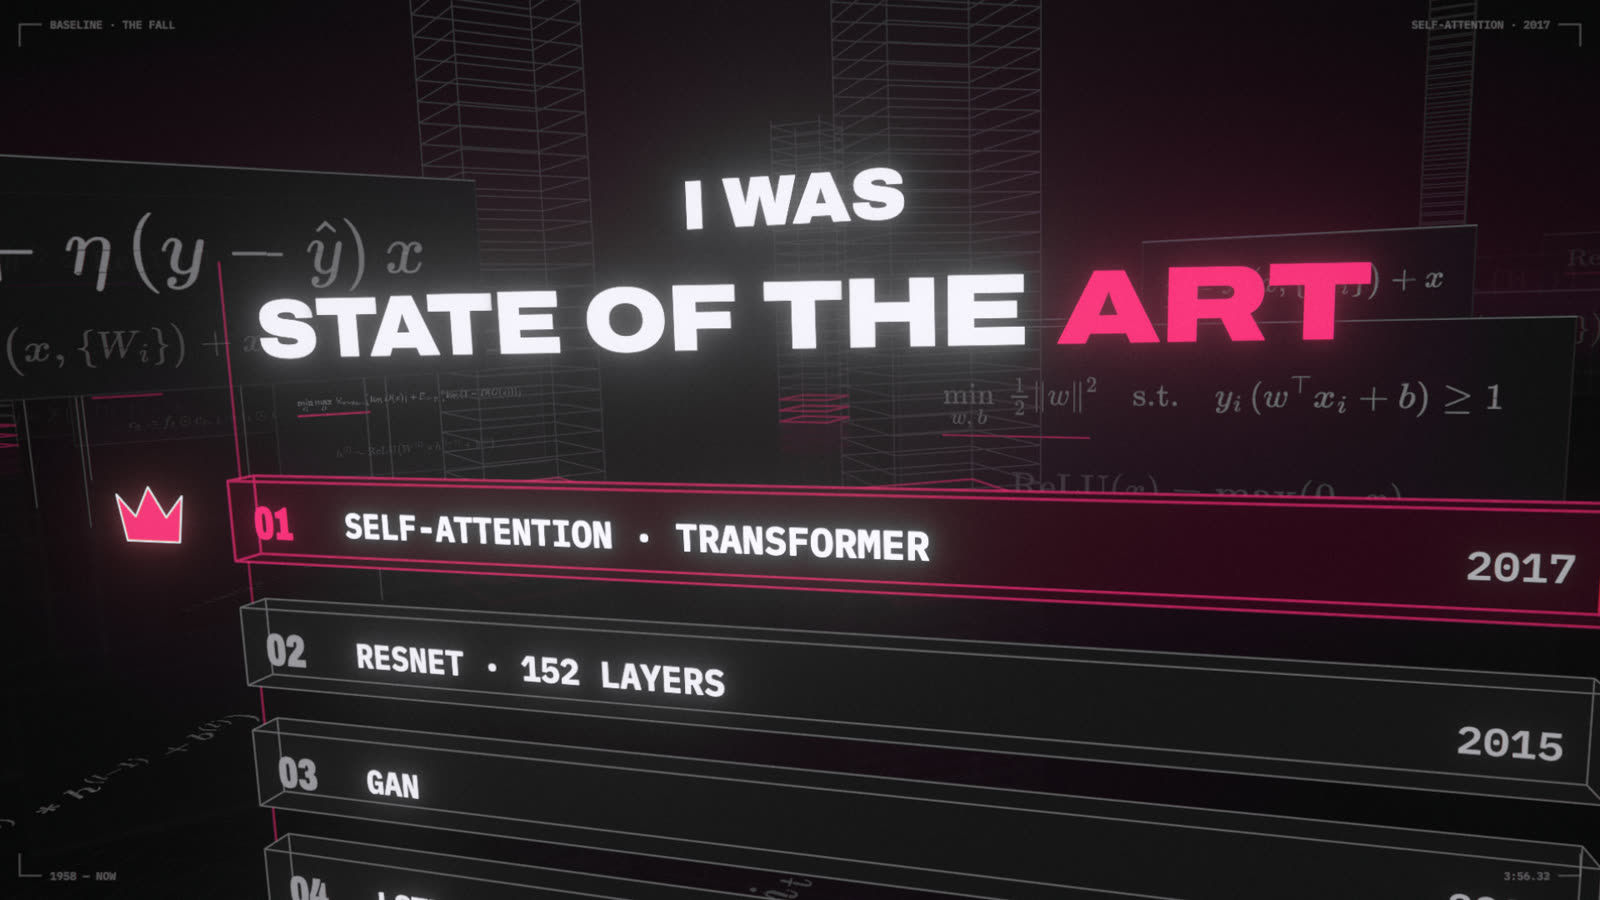

In [25]:
still(236.33)



---

### Checkpoint
1. Chinchilla says about 20 tokens per parameter. Why are widely deployed models usually trained on far more?
2. Where does attention's cost grow as n², and where does memory grow as n during generation?
3. FlashAttention computes exactly the same numbers as standard attention. What does it save, and how?
4. A model passes needle-in-a-haystack at 128K tokens. What does that tell you, and what doesn't it?
5. What does a linear-time model give up in exchange for constant cost per token?

<details><summary>Answers</summary>

1. Chinchilla minimizes *training* compute for a given loss. Serving costs about 2N per generated token, forever, so a smaller model trained longer (overtrained) costs a bit more to train but much less to run, and it fits cheaper hardware.
2. Computing the scores compares every pair of tokens: n² per head per layer. The KV cache stores keys and values for every past token: linear in n, and often the memory limit when serving.
3. Memory traffic. It processes keys and values in tiles that fit in fast on-chip SRAM and keeps the softmax's max and sum as running totals, so the n × n score table is never written to (or read back from) main memory.
4. That it can retrieve one planted fact at that length. Not that it can reason over, summarize or connect information spread across the whole document, which is much harder.
5. Exact recall. A fixed-size state can't store every past token, so copying or looking up a specific earlier detail gets harder. Hybrids keep a few full-attention layers for that.
</details>



### Final project (self-paced)
Pick a small dataset you care about: your team's support tickets, commit messages, log lines, product reviews. Then:
1. Split it into train / validation / test (Module 0).
2. Build the dumbest reasonable baseline and record its validation score.
3. Try a few-shot prompt with this course's LLM. Score it the same way.
4. If it's worth it, LoRA-fine-tune (Module 4) and score again.
5. Report all three on the **test** set once, in a little leaderboard of your own. Highlight the winner.

Then wait for the next deadline.



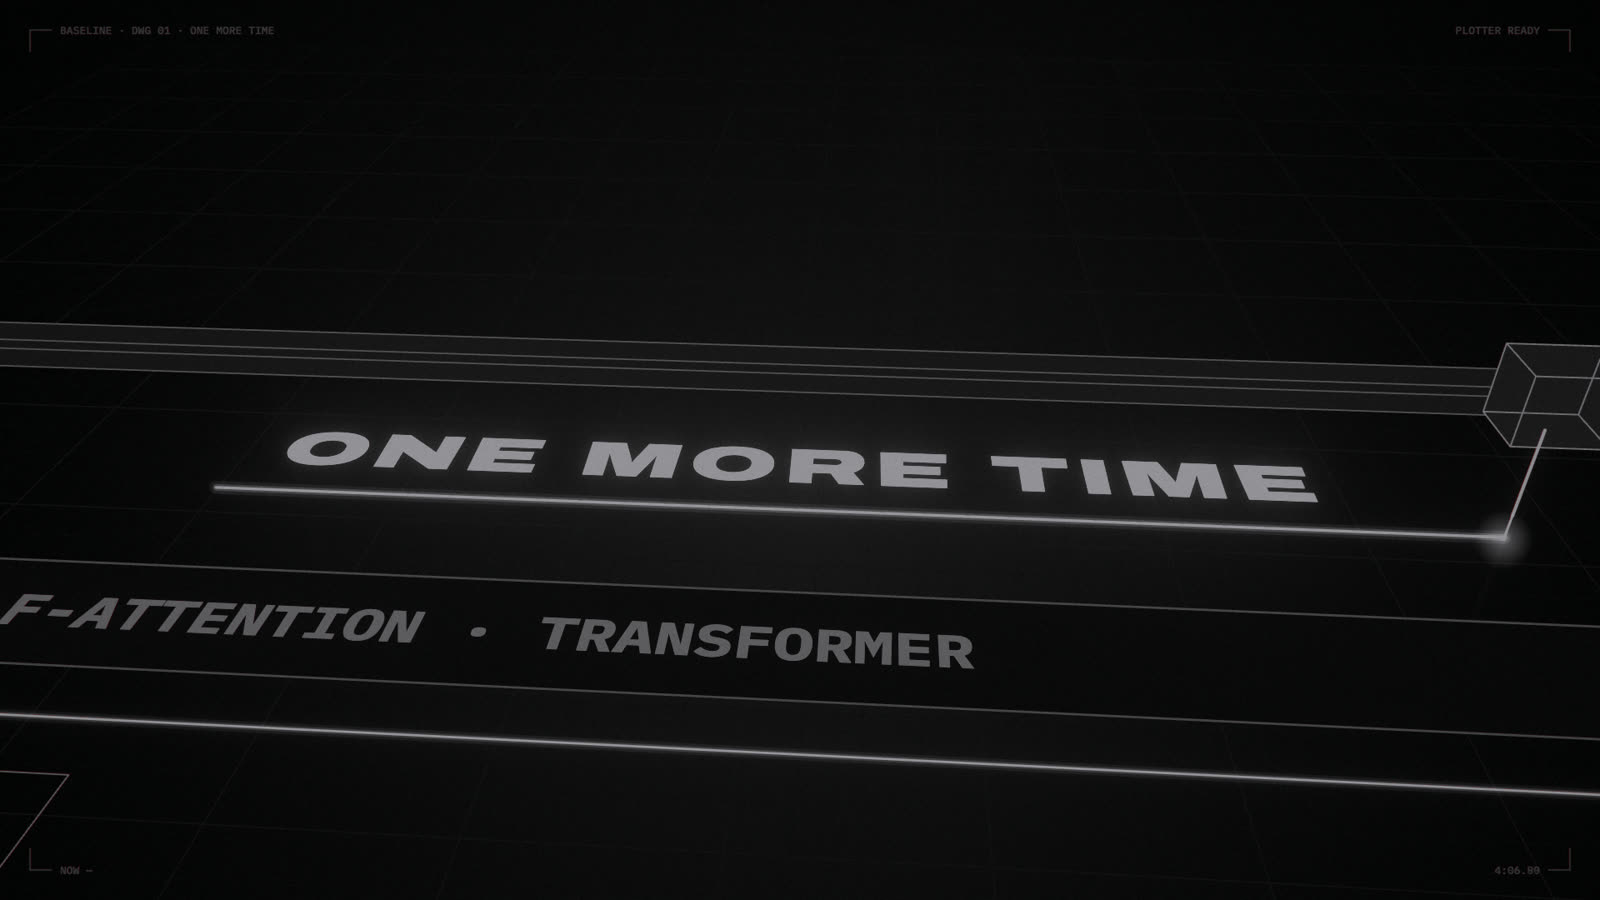

In [26]:
still(246.9)